In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
from torchvision.models import resnet18

CSV_PATH = Path("../raw/airbus-ship-detection/train_ship_segmentations_v2.csv")
DATA_DIR = Path("../raw/airbus-ship-detection/train_v2")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
class SimCLR(nn.Module):
    def __init__(self, projection_dim=128):
        super().__init__()

        backbone = resnet18(weights=None)

        # Replace the classification layer with an identity.
        feature_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()

        self.encoder = backbone

        self.projector = nn.Sequential(
            nn.Linear(feature_dim, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, projection_dim),
        )

    def forward(self, x):
        features = self.encoder(x)
        projections = self.projector(features)

        # Normalize projections for contrastive learning.
        projections = F.normalize(projections, dim=1)

        return features, projections

In [3]:
model = SimCLR().to(DEVICE)

print("Model initialized on:", DEVICE)
print(
    "Encoder feature dimension:",
    model.encoder.fc.in_features
    if isinstance(model.encoder.fc, nn.Linear)
    else 512,
)

Model initialized on: cuda
Encoder feature dimension: 512


In [4]:
annotations = pd.read_csv(CSV_PATH)

# An image is positive if it has at least one non-empty ship mask.
labels = (
    annotations.assign(has_ship=annotations["EncodedPixels"].notna())
    .groupby("ImageId")["has_ship"]
    .any()
    .astype(int)
)

print("Images with ships:", int(labels.sum()))
print("Images without ships:", int((labels == 0).sum()))

Images with ships: 42556
Images without ships: 150000


In [5]:
from sklearn.model_selection import train_test_split

positive_ids = labels[labels == 1].index.to_numpy()
negative_ids = labels[labels == 0].index.to_numpy()

rng = np.random.default_rng(42)

positive_sample = rng.choice(positive_ids, size=10_000, replace=False)
negative_sample = rng.choice(negative_ids, size=10_000, replace=False)

sample_ids = np.concatenate([positive_sample, negative_sample])
sample_labels = labels.loc[sample_ids].to_numpy()

train_ids, test_ids, y_train, y_test = train_test_split(
    sample_ids,
    sample_labels,
    test_size=0.2,
    random_state=42,
    stratify=sample_labels,
)

print("Training images:", len(train_ids))
print("Test images:", len(test_ids))

Training images: 16000
Test images: 4000


In [6]:
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

EVAL_TRANSFORM = transforms.Compose(
    [
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225),
        ),
    ]
)


class AirbusEvalDataset(Dataset):
    def __init__(self, image_ids, labels):
        self.image_ids = list(image_ids)
        self.labels = np.asarray(labels)
        self.image_dir = DATA_DIR

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_path = self.image_dir / self.image_ids[idx]

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image = EVAL_TRANSFORM(image)

        return image, int(self.labels[idx])


In [7]:
train_eval_dataset = AirbusEvalDataset(train_ids, y_train)
test_eval_dataset = AirbusEvalDataset(test_ids, y_test)

eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
)

test_loader = DataLoader(
    test_eval_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
)

In [8]:
def extract_features(encoder, loader):
    encoder.eval()
    all_features = []
    all_labels = []

    with torch.no_grad():
        for images, batch_labels in loader:
            images = images.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda"),
            ):
                features = encoder(images)

            all_features.append(features.float().cpu())
            all_labels.append(batch_labels)

    return (
        torch.cat(all_features),
        torch.cat(all_labels).long(),
    )


In [9]:
for parameter in model.encoder.parameters():
    parameter.requires_grad = False

train_features, train_targets = extract_features(model.encoder, eval_loader)

test_features, test_targets = extract_features(model.encoder, test_loader)

print("Train features:", train_features.shape)
print("Test features:", test_features.shape)

Train features: torch.Size([16000, 512])
Test features: torch.Size([4000, 512])


In [10]:
from torch.utils.data import TensorDataset

linear_model = nn.Linear(512, 2).to(DEVICE)

linear_optimizer = torch.optim.AdamW(
    linear_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

linear_train_loader = DataLoader(
    TensorDataset(train_features, train_targets),
    batch_size=256,
    shuffle=True,
)


In [11]:
for epoch in range(15):
    linear_model.train()
    total_loss = 0.0

    for features, targets in linear_train_loader:
        features = features.to(DEVICE)
        targets = targets.to(DEVICE)

        linear_optimizer.zero_grad()

        logits = linear_model(features)
        loss = F.cross_entropy(logits, targets)

        loss.backward()
        linear_optimizer.step()

        total_loss += loss.item() * len(targets)

    print(
        f"Epoch {epoch + 1:02d} | Loss: {total_loss / len(train_features):.4f}"
    )

Epoch 01 | Loss: 0.7012
Epoch 02 | Loss: 0.6812
Epoch 03 | Loss: 0.6663
Epoch 04 | Loss: 0.6571
Epoch 05 | Loss: 0.6481
Epoch 06 | Loss: 0.6422
Epoch 07 | Loss: 0.6348
Epoch 08 | Loss: 0.6292
Epoch 09 | Loss: 0.6236
Epoch 10 | Loss: 0.6190
Epoch 11 | Loss: 0.6214
Epoch 12 | Loss: 0.6171
Epoch 13 | Loss: 0.6136
Epoch 14 | Loss: 0.6136
Epoch 15 | Loss: 0.6091


In [12]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

linear_model.eval()

with torch.no_grad():
    logits = linear_model(test_features.to(DEVICE))
    predictions = logits.argmax(dim=1).cpu().numpy()

y_true = test_targets.numpy()

print(f"Accuracy:  {accuracy_score(y_true, predictions):.4f}")
print(f"Precision: {precision_score(y_true, predictions):.4f}")
print(f"Recall:    {recall_score(y_true, predictions):.4f}")
print(f"F1-score:  {f1_score(y_true, predictions):.4f}")
print("\nConfusion matrix:")
print(confusion_matrix(y_true, predictions))
print("\nClassification report:")
print(
    classification_report(
        y_true, predictions, target_names=["No ship", "Ship"]
    )
)

Accuracy:  0.6903
Precision: 0.7371
Recall:    0.5915
F1-score:  0.6563

Confusion matrix:
[[1578  422]
 [ 817 1183]]

Classification report:
              precision    recall  f1-score   support

     No ship       0.66      0.79      0.72      2000
        Ship       0.74      0.59      0.66      2000

    accuracy                           0.69      4000
   macro avg       0.70      0.69      0.69      4000
weighted avg       0.70      0.69      0.69      4000



In [13]:
import matplotlib.pyplot as plt

# Use the predictions and labels already computed in Cell 6.
results_df = pd.DataFrame(
    {
        "image_id": test_ids,
        "actual": y_true,
        "predicted": predictions,
    }
)

results_df["correct"] = results_df["actual"] == results_df["predicted"]

results_df["actual_label"] = results_df["actual"].map(
    {
        0: "No ship",
        1: "Ship",
    }
)

results_df["predicted_label"] = results_df["predicted"].map(
    {
        0: "No ship",
        1: "Ship",
    }
)

print(
    results_df["correct"]
    .value_counts()
    .rename(
        {
            True: "Correct",
            False: "Incorrect",
        }
    )
)

results_df.head()

correct
Correct      2761
Incorrect    1239
Name: count, dtype: int64


,image_id,actual,predicted,correct,actual_label,predicted_label
0,2abea30b1.jpg,1,1,True,Ship,Ship
1,7bf1aaa2c.jpg,0,0,True,No ship,No ship
2,242f1a95e.jpg,0,0,True,No ship,No ship
3,629e69227.jpg,1,1,True,Ship,Ship
4,fe0fb2688.jpg,0,0,True,No ship,No ship


In [14]:
def show_predictions(results, category, n=8, seed=42):
    subset = results[category].copy()

    if subset.empty:
        print("No examples found for this category.")
        return

    subset = subset.sample(
        n=min(n, len(subset)),
        random_state=seed,
    )

    cols = 4
    rows = (len(subset) + cols - 1) // cols

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(14, 3.8 * rows),
        squeeze=False,
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, row) in zip(axes.flat, subset.iterrows()):
        image_path = DATA_DIR / row["image_id"]

        with Image.open(image_path) as image:
            ax.imshow(image.convert("RGB"))

        status = "CORRECT" if row["correct"] else "INCORRECT"

        ax.set_title(
            f"Actual: {row['actual_label']}\n"
            f"Predicted: {row['predicted_label']} | {status}",
            fontsize=9,
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

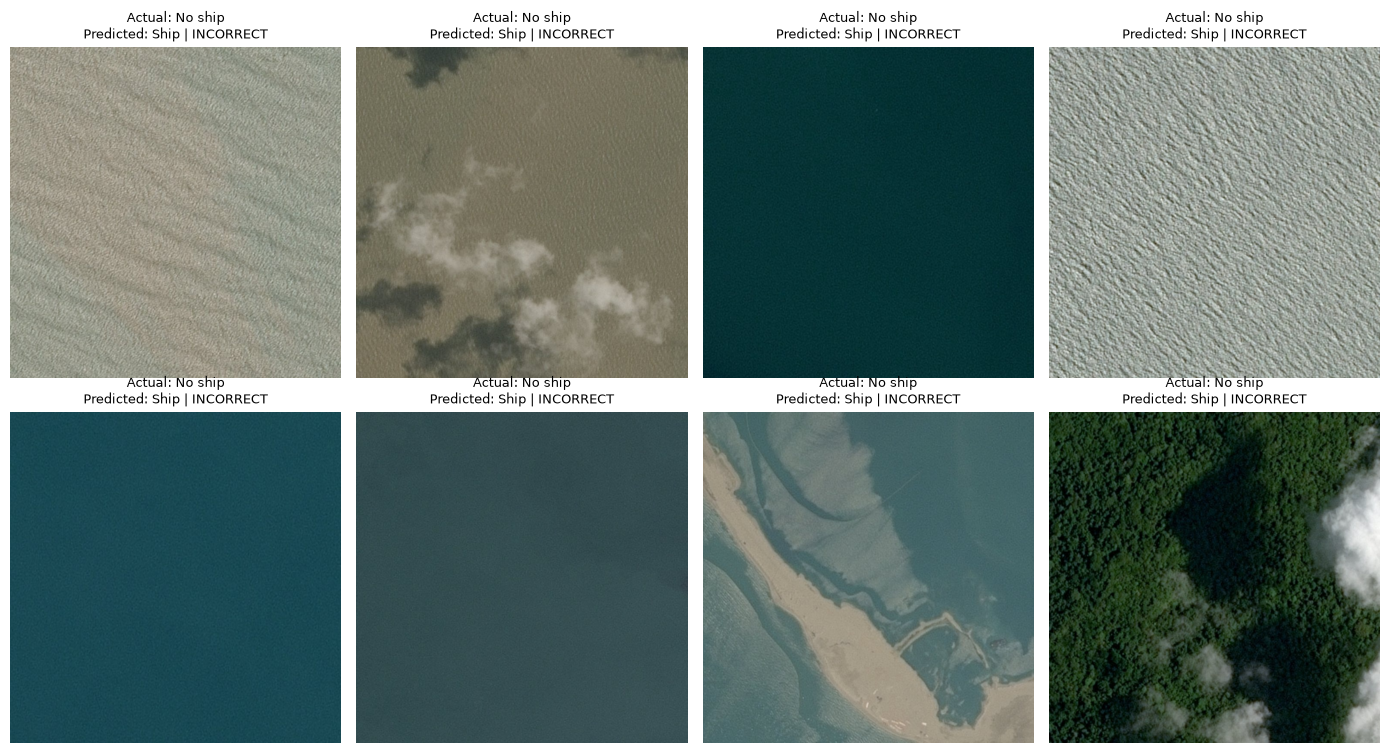

In [15]:
false_positives = (results_df["actual"] == 0) & (results_df["predicted"] == 1)

show_predictions(results_df, false_positives, n=8)

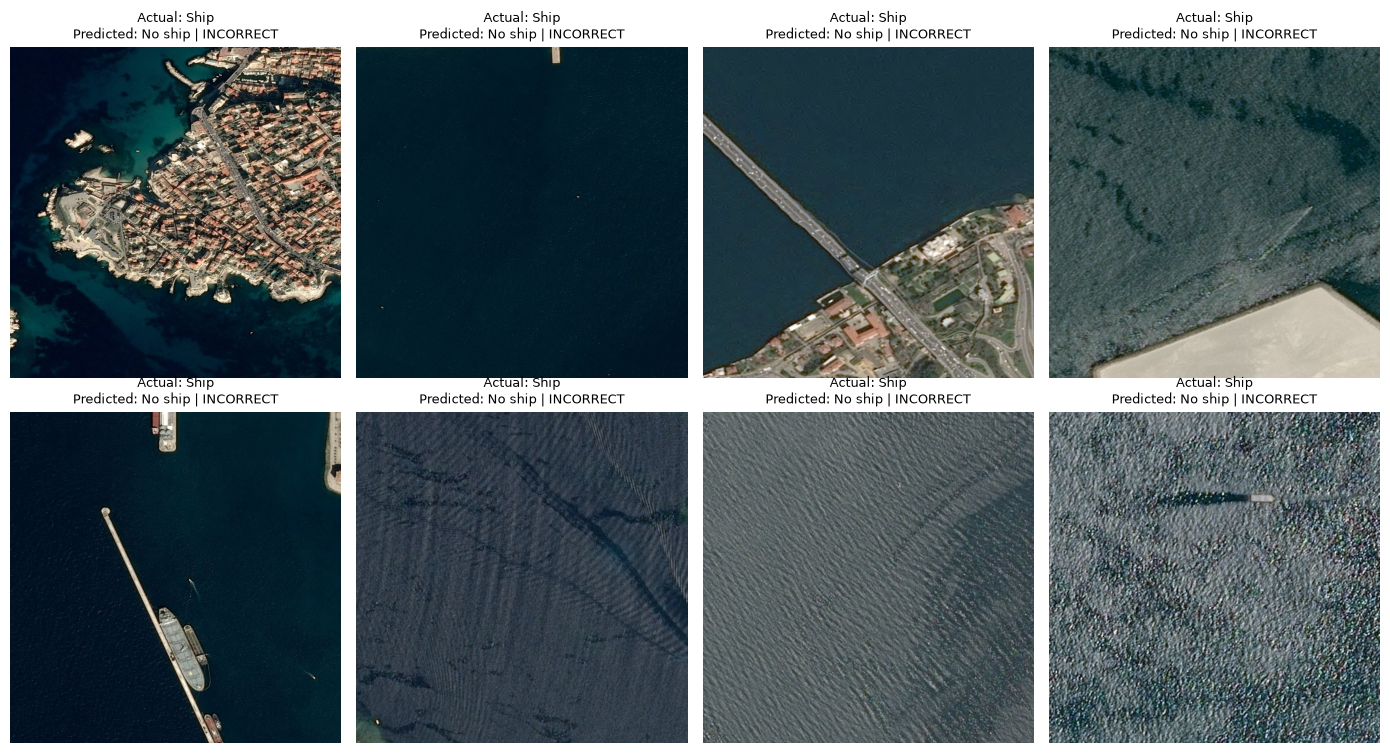

In [16]:
false_negatives = (results_df["actual"] == 1) & (results_df["predicted"] == 0)

show_predictions(results_df, false_negatives, n=8)

Correct ship predictions: 1183
Correct no-ship predictions: 1578


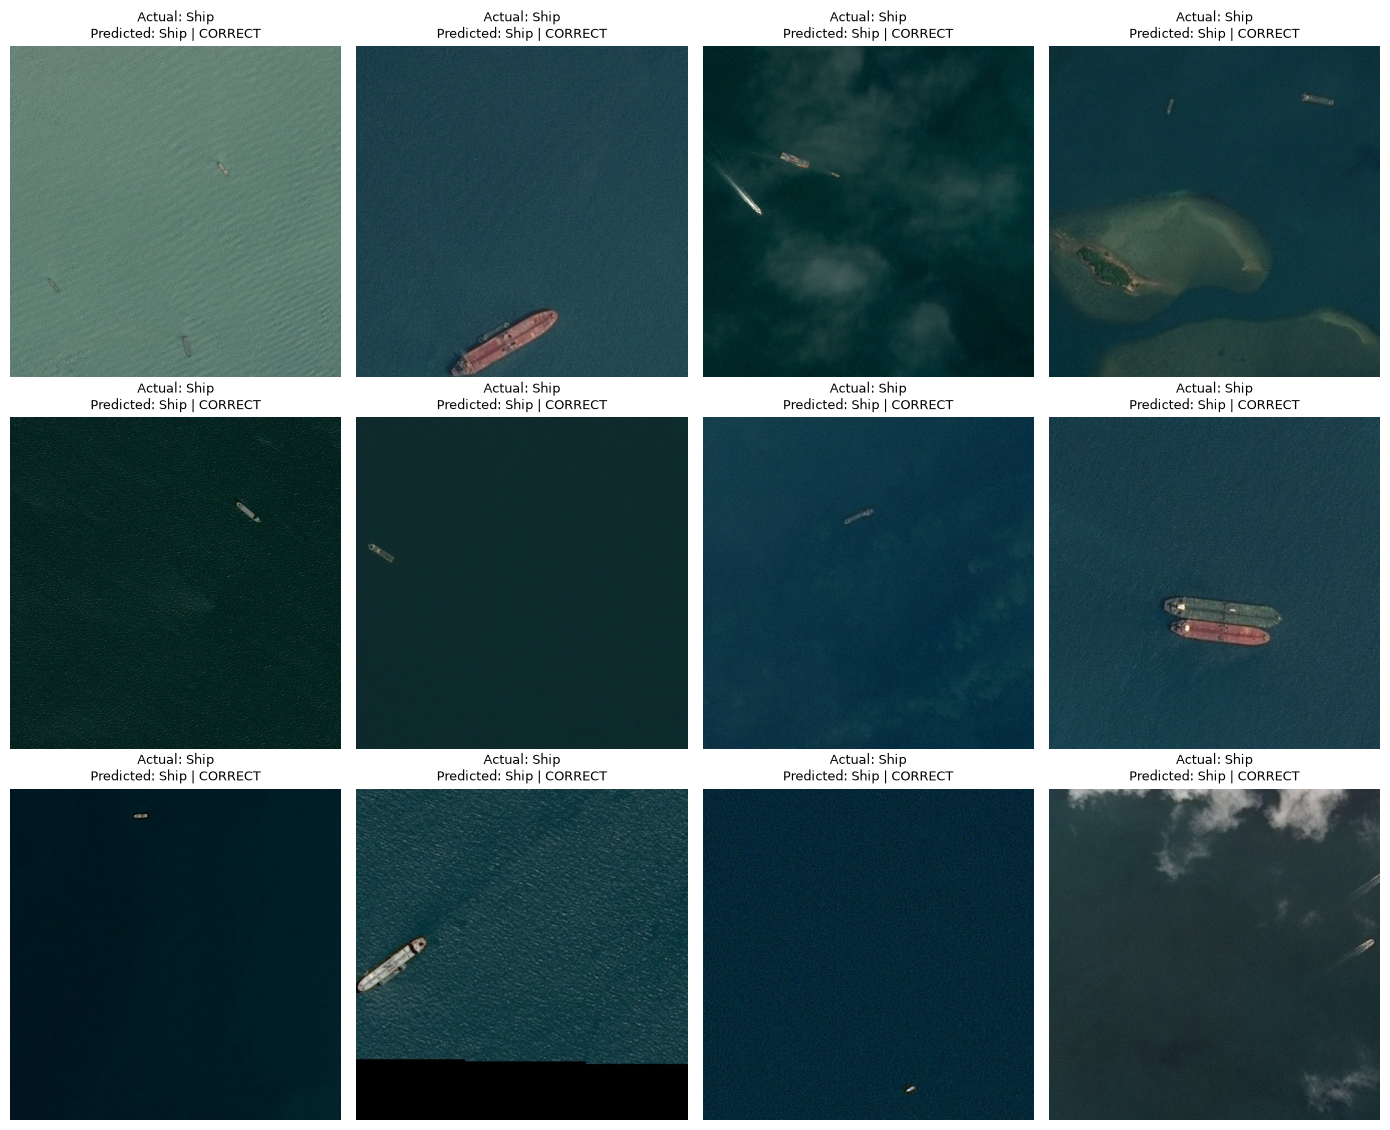

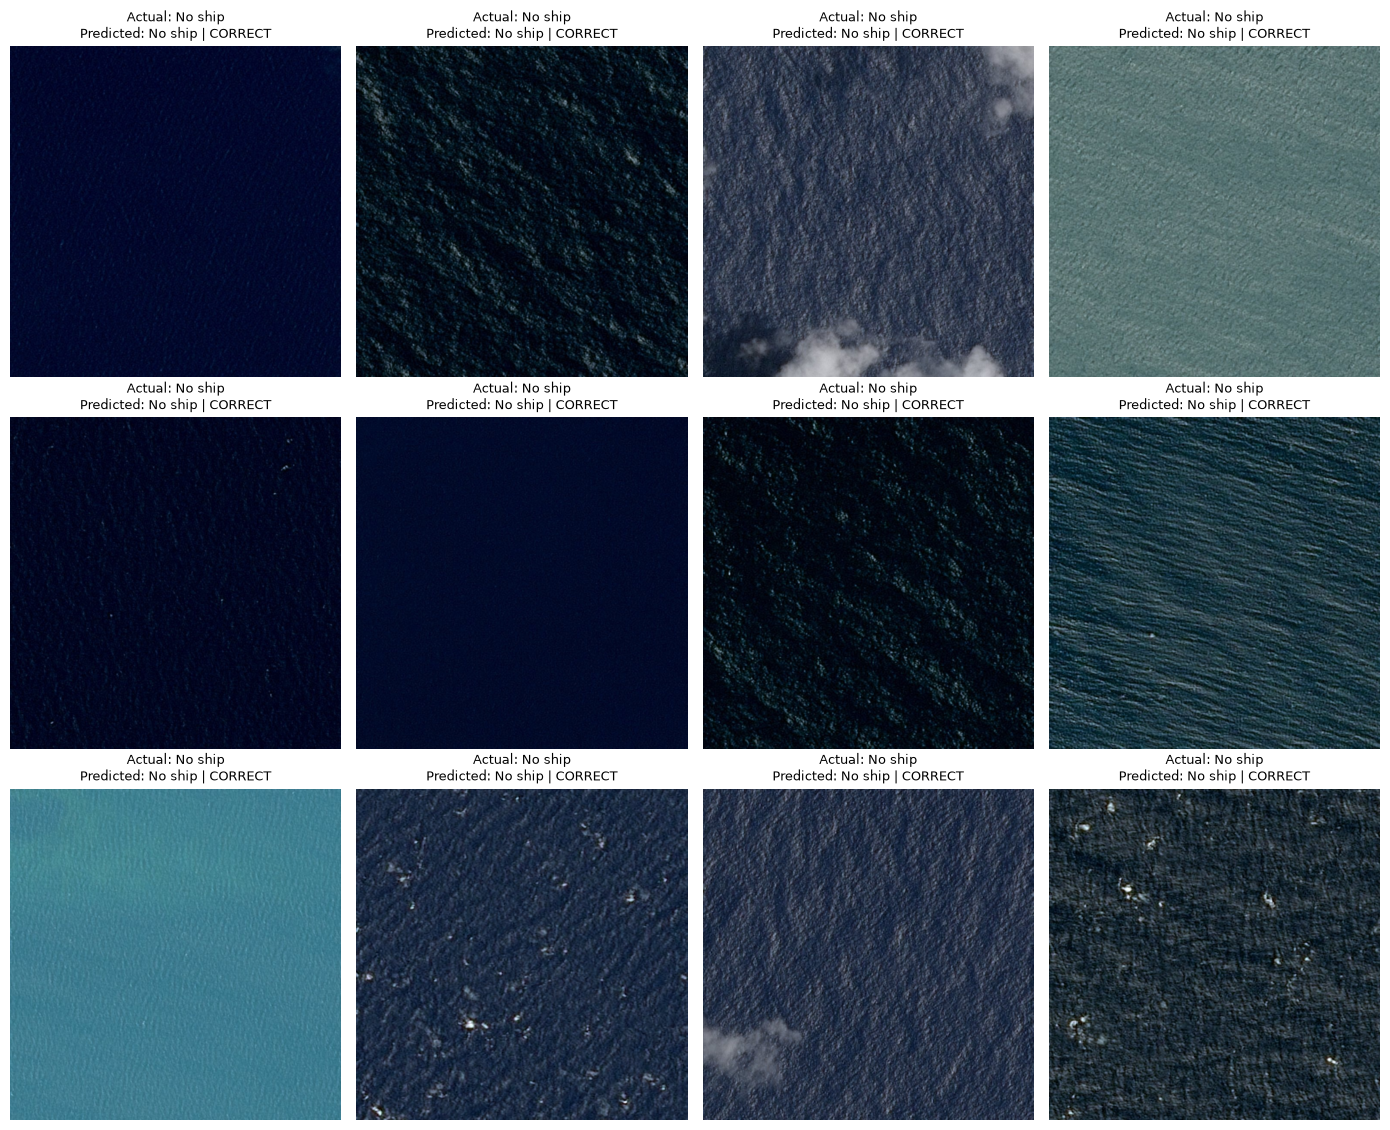

In [17]:
# Correctly predicted images containing ships
correct_ships = (results_df["actual"] == 1) & (results_df["predicted"] == 1)

# Correctly predicted images without ships
correct_no_ships = (results_df["actual"] == 0) & (results_df["predicted"] == 0)

print("Correct ship predictions:", correct_ships.sum())
print("Correct no-ship predictions:", correct_no_ships.sum())

show_predictions(results_df, correct_ships, n=12)
show_predictions(results_df, correct_no_ships, n=12)